# 02 · Make training patches (5 m labels, 20 m inputs)

**Milestone 2 of the Lunar Hazard Map.** This notebook turns the 87–90°S area into training examples for the U-Net. Each example is a 2.56 × 2.56 km square:

- **Input:** what NASA's 20 m maps show there (128 × 128 pixels, 6 layers). This is all the model gets, the same as anywhere else on the pole.
- **Answer:** the safe / caution / no-go class of every 5 m pixel (512 × 512), from the 5 m slope.

It also re-checks the Milestone 1 result. M1 found the simple 20 m slope rule catches 98% of no-go ground, but that was one 12 km window that is 64% steep crater wall. Here the same test runs over the **whole 87–90°S area**, split by terrain type, using **NASA's real 20 m map** instead of our averaged 5 m map. The "mostly drivable" row is the one that matters for routes.

**Before running**, download three NASA 20 m files (about 4 GB, separate terminal tab): `bash download_m2.sh`. You also need `ldem_87s_5mpp.tif` and `ldec_87s_5mpp.tif` from Milestone 1. The 4.9 GB 5 m slope file is **not** needed: Section F of notebook 01 showed slope computed from the 5 m elevation matches NASA's 5 m slope (median difference 0.00°, measured).

**Number labels.** *Sourced* = from a cited page or paper. *Placeholder* = a setting we picked that still has to be confirmed. *Measured* = computed here from the data.


**Data citations:** Barker et al. 2023, *Planet. Sci. J.* 4, 183, doi:10.3847/PSJ/acf3e1 (20 m elevation, shot counts, PSR map). Barker et al. 2021, *Planet. Space Sci.* 203, 105119, doi:10.1016/j.pss.2020.105119 (5 m mosaic).

## Setup

In [1]:
import os, json, time, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle
import rasterio
from rasterio.windows import Window, from_bounds

plt.rcParams.update({"figure.dpi": 110, "image.origin": "upper"})
pd.set_option("display.width", 160)

In [2]:
# ---------------- Settings ----------------
DATA = Path(os.environ.get("LUNAR_DATA", Path.home() / "lunar" / "data"))
PATCHES = DATA / "patches"              # ~1 GB of .npz files, outside git
FIG = Path("figures"); RESULTS = Path("results")
for d in (PATCHES, FIG, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

F5 = {"elev": DATA / "ldem_87s_5mpp.tif",            # 5 m elevation, 87-90 S (from M1)
      "count": DATA / "ldec_87s_5mpp.tif"}           # 5 m LOLA shots per pixel (from M1)
F20 = {"elev": DATA / "LDEM_80S_20MPP_ADJ.TIF",      # 20 m elevation, 80-90 S (download_m2.sh)
       "count": DATA / "LDEC_80S_20MPP_ADJ.TIF",     # 20 m LOLA shots per pixel
       "psr": DATA / "LPSR_80S_20MPP_ADJ.TIF"}       # 20 m permanently shadowed regions

# Hazard thresholds (degrees), same as notebook 01
SAFE_MAX_DEG = 15.0   # SOURCED: NASA VIPER page, "capable of traversing an incline of as much as 15 degrees"
NOGO_MIN_DEG = 25.0   # PLACEHOLDER: from the project plan, not tied to a specific rover yet

MOON_R = 1_737_400.0  # m, LOLA reference sphere
LAT_LIMIT = -87.0     # SOURCED: the 5 m mosaic covers 87-90 S (PGDA)

PATCH5 = 512                    # answer patch, 5 m pixels (2.56 km)
SCALE = 4                       # 20 m / 5 m
PATCH20 = PATCH5 // SCALE       # input patch, 128 x 128 (same size as the landslide project)
HALO20 = 2                      # extra 20 m pixels read around each patch so slopes have no edge effects
HALO5 = HALO20 * SCALE
MIN_VALID = 0.98                # skip patches with more than 2% missing 5 m data (setting)

BLOCK = int(os.environ.get("LUNAR_BLOCK", 8))  # split block = BLOCK x BLOCK patches (8 -> 20.5 km), setting
SPLIT_FRAC = {"test": 0.15, "val": 0.15}       # rest is train (setting)
SEED = 23

# Terrain bins by how much of the patch is no-go at 5 m (PLACEHOLDER bins, for reporting only)
STRATA = [(0.0, 0.10, "mostly drivable"), (0.10, 0.50, "mixed"), (0.50, 1.01, "mostly steep")]

# Milestone 1 study window (Shackleton rim to floor). Forced into the test split.
SHACKLETON_LAT, SHACKLETON_LON = -89.67, 129.78   # SOURCED: USGS Gazetteer
CROP_KM = 12.0

OVERWRITE = False     # True = rewrite patch files that already exist

missing = [p.name for p in [*F5.values(), *F20.values()] if not p.exists()]
if missing:
    raise FileNotFoundError(f"Missing in {DATA}: {missing}\nRun download_m2.sh in a separate terminal tab first.")
print("Data folder:", DATA)
print("All 5 m and 20 m files found.")

Data folder: /Users/razbinkarkidoli/lunar/data
All 5 m and 20 m files found.


In [3]:
# ---------------- Helpers ----------------
def read(path, window=None):
    # Band 1 as float32, every kind of no-data -> NaN. Returns (array, transform).
    with rasterio.open(path) as s:
        a = s.read(1, window=window, masked=True)
        t = s.window_transform(window) if window is not None else s.transform
    a = np.ma.filled(a.astype("float32"), np.nan)
    a[~np.isfinite(a) | (np.abs(a) > 1e30)] = np.nan
    return a, t

def read_src(src, window):
    a = np.ma.filled(src.read(1, window=window, masked=True).astype("float32"), np.nan)
    a[~np.isfinite(a) | (np.abs(a) > 1e30)] = np.nan
    return a

def latlon_to_xy(lat, lon):
    rho = 2 * MOON_R * np.tan(np.radians(90 + np.asarray(lat)) / 2)
    return rho * np.sin(np.radians(lon)), rho * np.cos(np.radians(lon))

def xy_to_latlon(x, y):
    rho = np.hypot(x, y)
    lat = -(90 - np.degrees(2 * np.arctan(rho / (2 * MOON_R))))
    return lat, np.degrees(np.arctan2(x, y)) % 360

def slope_deg(dem, res):
    gy, gx = np.gradient(dem, res)
    return np.degrees(np.arctan(np.hypot(gx, gy))).astype("float32")

def bumpiness(dem):
    # |Laplacian| in metres: how much a pixel sticks up or down from its 4 neighbours.
    # A cheap roughness proxy that ignores plain tilt. Edge pixels are NaN.
    out = np.full(dem.shape, np.nan, "float32")
    out[1:-1, 1:-1] = np.abs(dem[1:-1, 2:] + dem[1:-1, :-2] + dem[2:, 1:-1] + dem[:-2, 1:-1] - 4 * dem[1:-1, 1:-1])
    return out

def hillshade(dem, res, azimuth=45, altitude=45):
    gy, gx = np.gradient(dem, res)
    slope = np.arctan(np.hypot(gx, gy)); aspect = np.arctan2(-gy, -gx)
    az, zen = np.radians(360 - azimuth + 90), np.radians(90 - altitude)
    hs = np.cos(zen) * np.cos(slope) + np.sin(zen) * np.sin(slope) * np.cos(az - aspect)
    return np.clip(hs, 0, 1).astype("float32")

NODATA_CLASS = 255
CLASS_NAMES = ["safe", "caution", "no-go"]
CLASS_CMAP = ListedColormap(["#2e9e5b", "#f0b429", "#d64545"])

def classify(slope):
    c = np.full(slope.shape, NODATA_CLASS, np.uint8)
    ok = np.isfinite(slope)
    c[ok & (slope < SAFE_MAX_DEG)] = 0
    c[ok & (slope >= SAFE_MAX_DEG) & (slope < NOGO_MIN_DEG)] = 1
    c[ok & (slope >= NOGO_MIN_DEG)] = 2
    return c

def prf(tp, fn, fp):
    rec = tp / (tp + fn) if tp + fn else np.nan
    prec = tp / (tp + fp) if tp + fp else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else np.nan
    return rec, prec, f1

def show_classes(ax, c, extent, title):
    ax.imshow(np.ma.masked_equal(c, NODATA_CLASS), cmap=CLASS_CMAP, vmin=-0.5, vmax=2.5,
              extent=extent, interpolation="nearest")
    ax.set_title(title, fontsize=9)

SHACK_XY = latlon_to_xy(SHACKLETON_LAT, SHACKLETON_LON)
_cx, _cy = SHACK_XY[0] / 2, SHACK_XY[1] / 2          # midpoint between pole and Shackleton center (as in 01)
_h = CROP_KM * 1000 / 2
M1_BOUNDS = (_cx - _h, _cy - _h, _cx + _h, _cy + _h)   # left, bottom, right, top (m)
R87 = 2 * MOON_R * np.tan(np.radians(90 + LAT_LIMIT) / 2)
print(f"87 S circle radius: {R87 / 1e3:.2f} km")

87 S circle radius: 90.99 km


## A · Do the 5 m and 20 m grids line up?

Each 20 m pixel should sit exactly on top of a 4 × 4 block of 5 m pixels. If the two grids are offset by a fraction of a pixel, the answers and inputs would be shifted against each other and training would be noisy. This finds where the grids meet and starts the patch grid there.

In [4]:
with rasterio.open(F5["elev"]) as s:
    t5, W5, H5, crs5 = s.transform, s.width, s.height, s.crs
with rasterio.open(F5["count"]) as s:
    assert s.transform == t5 and (s.width, s.height) == (W5, H5), "5 m elevation and count grids differ"
info20 = {}
for k, p in F20.items():
    with rasterio.open(p) as s:
        info20[k] = dict(file=p.name, width=s.width, height=s.height, pixel_m=s.transform.a,
                         dtype=s.dtypes[0], nodata=s.nodata, tiled=s.profile.get("tiled"), transform=s.transform)
display(pd.DataFrame(info20).T.drop(columns="transform"))
t20 = info20["elev"]["transform"]
assert all(v["transform"] == t20 for v in info20.values()), "the three 20 m files are on different grids"
assert abs(t5.a - 5) < 1e-6 and abs(t20.a - 20) < 1e-6, (t5.a, t20.a)

with rasterio.open(F20["elev"]) as s:
    crs20 = s.crs
same = crs5 == crs20
print("5 m CRS :", crs5.to_wkt()[:120], "...")
print("20 m CRS:", crs20.to_wkt()[:120], "...")
print("Same CRS object:", same, "" if same else "(names differ; both should be south polar stereographic on the 1737.4 km sphere, check the two lines above)")

# Shift (in 5 m pixels) that puts patch corners on 20 m pixel corners
c_shift = ((t20.c - t5.c) % 20) / 5
r_shift = ((t5.f - t20.f) % 20) / 5
assert abs(c_shift - round(c_shift)) < 1e-6 and abs(r_shift - round(r_shift)) < 1e-6, \
    f"20 m grid is not offset by whole 5 m pixels ({c_shift}, {r_shift}); needs resampling"
c_shift, r_shift = int(round(c_shift)) % 4, int(round(r_shift)) % 4
print(f"5 m grid: {W5} x {H5} px, origin ({t5.c / 1e3:.2f}, {t5.f / 1e3:.2f}) km")
print(f"Patch grid starts {c_shift} col(s) and {r_shift} row(s) in so 4x4 blocks match 20 m pixels")

,file,width,height,pixel_m,dtype,nodata,tiled
elev,LDEM_80S_20MPP_ADJ.TIF,30400,30400,20.0,float32,NaN,True
count,LDEC_80S_20MPP_ADJ.TIF,30400,30400,20.0,float32,NaN,True
psr,LPSR_80S_20MPP_ADJ.TIF,30400,30400,20.0,float32,NaN,True


5 m CRS : PROJCS["Moon2000_spole",GEOGCS["GCS_Moon",DATUM["D_Moon_2000",SPHEROID["Moon_2000_IAU_IAG",1737400,0]],PRIMEM["Reference ...
20 m CRS: PROJCS["Moon (2015) - Sphere / Ocentric / South Polar",GEOGCS["Moon (2015) - Sphere / Ocentric",DATUM["Moon (2015) - Sph ...
Same CRS object: False (names differ; both should be south polar stereographic on the 1737.4 km sphere, check the two lines above)
5 m grid: 40000 x 40000 px, origin (-100.00, 100.00) km
Patch grid starts 0 col(s) and 0 row(s) in so 4x4 blocks match 20 m pixels


In [5]:
# Load the part of the 20 m maps that overlaps the 5 m mosaic (inside the 87 S circle) into memory once.
x_lo, x_hi = max(t5.c, -R87), min(t5.c + W5 * 5, R87)
y_lo, y_hi = max(t5.f - H5 * 5, -R87), min(t5.f, R87)
pad = (HALO20 + 2) * 20
w = from_bounds(x_lo - pad, y_lo - pad, x_hi + pad, y_hi + pad, transform=t20)
w = Window(int(math.floor(w.col_off)), int(math.floor(w.row_off)), int(math.ceil(w.width)), int(math.ceil(w.height)))
w = w.intersection(Window(0, 0, info20["elev"]["width"], info20["elev"]["height"]))

t0 = time.time()
elev20_all, tE = read(F20["elev"], w)
cnt, _ = read(F20["count"], w)
logcnt20_all = np.log1p(np.nan_to_num(cnt, nan=0.0).clip(min=0)).astype("float16"); del cnt
with rasterio.open(F20["psr"]) as s:
    p = s.read(1, window=w, masked=True)
    psr_vals = np.unique(np.ma.compressed(p[::50, ::50]))
psr20_all = (np.ma.filled(p, 0) > 0).astype("uint8"); del p
print(f"20 m crop {elev20_all.shape} read in {time.time() - t0:.0f} s, "
      f"{(elev20_all.nbytes + logcnt20_all.nbytes + psr20_all.nbytes) / 1e6:.0f} MB in memory")
print("PSR map values seen (sample):", psr_vals[:10], "-> treating > 0 as shadowed")

def rc20(x, y):
    return int(round((tE.f - y) / 20)), int(round((x - tE.c) / 20))
r, c = rc20(*SHACK_XY)
print("PSR flag at Shackleton center (should be 1):", int(psr20_all[r, c]))
print(f"Shadowed share of the 87-90 S crop (measured): {psr20_all.mean():.1%}")

20 m crop (9108, 9108) read in 4 s, 581 MB in memory
PSR map values seen (sample): [0. 1.] -> treating > 0 as shadowed
PSR flag at Shackleton center (should be 1): 1
Shadowed share of the 87-90 S crop (measured): 18.0%


## B · Was the Milestone 1 number too optimistic?

Milestone 1 made its "20 m" map by averaging the 5 m map. The real NASA 20 m map is built separately from the laser shots, so it can disagree. This repeats M1's test on the same Shackleton window both ways, and checks for a small shift between the two maps.

In [6]:
def scores(truth, pred, m):
    t, p = (truth == 2) & m, (pred == 2) & m
    rec, prec, f1 = prf(int((t & p).sum()), int((t & ~p).sum()), int((~t & p).sum()))
    return dict(nogo_recall=rec, nogo_precision=prec, nogo_f1=f1, class_agreement=float((truth[m] == pred[m]).mean()))

wb = from_bounds(*M1_BOUNDS, transform=t5)
r0 = int(round(wb.row_off)); c0 = int(round(wb.col_off))
r0 += (r_shift - r0) % 4; c0 += (c_shift - c0) % 4          # snap to the 20 m grid
n4 = (int(round(wb.width)) - 8) // 4 * 4
win5 = Window(c0 - HALO5, r0 - HALO5, n4 + 2 * HALO5, n4 + 2 * HALO5)
e5h, t5w = read(F5["elev"], win5)
truth = classify(slope_deg(e5h, 5)[HALO5:-HALO5, HALO5:-HALO5])
k = n4 // 4

# (a) M1 method: average the 5 m elevation to 20 m
ba = e5h.reshape(e5h.shape[0] // 4, 4, e5h.shape[1] // 4, 4).mean(axis=(1, 3))
cls_ba = classify(slope_deg(ba, 20)[HALO20:-HALO20, HALO20:-HALO20])
# (b) NASA's 20 m elevation for the same pixels
x0, y0 = t5w.c, t5w.f
rr, cc = rc20(x0, y0)
nasa = elev20_all[rr:rr + ba.shape[0], cc:cc + ba.shape[1]]
cls_nasa = classify(slope_deg(nasa, 20)[HALO20:-HALO20, HALO20:-HALO20])

# Shift check: which small offset makes NASA 20 m match the averaged 5 m best?
best = None
core = slice(4, -4)
for dy in range(-2, 3):
    for dx in range(-2, 3):
        a = nasa[core, core]; b = np.roll(np.roll(ba, dy, 0), dx, 1)[core, core]
        d = a - b; d = d - np.nanmedian(d)
        rms = float(np.sqrt(np.nanmean(d ** 2)))
        if best is None or rms < best[0]:
            best = (rms, dy, dx)
d0 = nasa - ba
B = dict(median_offset_m=float(np.nanmedian(d0)),
         median_abs_diff_m=float(np.nanmedian(np.abs(d0 - np.nanmedian(d0)))),
         best_shift_px=[best[1], best[2]], rms_at_best_shift_m=best[0])
print("NASA 20 m vs averaged 5 m elevation (measured):", {k_: (round(v, 2) if isinstance(v, float) else v) for k_, v in B.items()})
if B["best_shift_px"] != [0, 0]:

up = lambda c: np.repeat(np.repeat(c, 4, 0), 4, 1)
m = np.zeros(truth.shape, bool); m[16:-16, 16:-16] = True
m &= (truth != NODATA_CLASS) & (up(cls_ba) != NODATA_CLASS) & (up(cls_nasa) != NODATA_CLASS)
Btab = pd.DataFrame([dict(method="20 m rule, averaged 5 m (M1 method)", **scores(truth, up(cls_ba), m)),
                     dict(method="20 m rule, NASA 20 m map", **scores(truth, up(cls_nasa), m))]).round(3)
display(Btab)
B["m1_window_scores"] = Btab.to_dict(orient="records")

NASA 20 m vs averaged 5 m elevation (measured): {'median_offset_m': 0.06, 'median_abs_diff_m': 0.45, 'best_shift_px': [0, 0], 'rms_at_best_shift_m': 0.78}


,method,nogo_recall,nogo_precision,nogo_f1,class_agreement
0,"20 m rule, averaged 5 m (M1 method)",0.981,0.964,0.973,0.950
1,"20 m rule, NASA 20 m map",0.979,0.961,0.970,0.946


## C · Patch grid and train / val / test split

The 87–90°S area is cut into 2.56 km patches. Whole **blocks** of patches (about 20 km across) go to train, val or test, so the test areas are places the model has never seen. Train and val patches that touch a block of another split are dropped (**buffer**) so nothing leaks across the border. The Shackleton window from Milestone 1 is always in **test**, since it's Lantern Profile 1.

In [7]:
first_r, first_c = r_shift + HALO5, c_shift + HALO5
nI = (H5 - first_r - HALO5) // PATCH5
nJ = (W5 - first_c - HALO5) // PATCH5
side = PATCH5 * 5

grid = []
for i in range(nI):
    for j in range(nJ):
        r0, c0 = first_r + i * PATCH5, first_c + j * PATCH5
        x0, y0 = t5.c + c0 * 5, t5.f - r0 * 5                  # top-left corner (m)
        corners = np.array([[x0, y0], [x0 + side, y0], [x0, y0 - side], [x0 + side, y0 - side]])
        if np.hypot(corners[:, 0], corners[:, 1]).max() > R87:
            continue
        rr, cc = rc20(x0, y0)
        if rr - HALO20 < 0 or cc - HALO20 < 0 or rr + PATCH20 + HALO20 > elev20_all.shape[0] \
                or cc + PATCH20 + HALO20 > elev20_all.shape[1]:
            continue
        in_m1 = not (x0 + side <= M1_BOUNDS[0] or x0 >= M1_BOUNDS[2] or y0 <= M1_BOUNDS[1] or y0 - side >= M1_BOUNDS[3])
        grid.append(dict(i=i, j=j, r0=r0, c0=c0, x0=x0, y0=y0, block=(i // BLOCK, j // BLOCK), in_m1=in_m1))
G = pd.DataFrame(grid)
print(f"{len(G)} patch positions fully inside 87 S ({nI} x {nJ} grid)")

# Assign whole blocks to splits, by patch count
rng = np.random.default_rng(SEED)
nblk = G.groupby("block").size()
forced = sorted(set(G.loc[G.in_m1, "block"]))
others = [b for b in nblk.index if b not in forced]
rng.shuffle(others)
need = {k: f * len(G) for k, f in SPLIT_FRAC.items()}
have = {"test": 0, "val": 0, "train": 0}
split_of = {}
for b in forced:
    split_of[b] = "test"; have["test"] += nblk[b]
for b in others:
    s = "test" if have["test"] < need["test"] else "val" if have["val"] < need["val"] else "train"
    split_of[b] = s; have[s] += nblk[b]
G["split"] = G.block.map(split_of)

# Buffer: drop train/val patches that touch a different split
pos = {(a, b): s for a, b, s in zip(G.i, G.j, G.split)}
def touches_other(i, j, s):
    return any(pos.get((i + di, j + dj), s) != s for di in (-1, 0, 1) for dj in (-1, 0, 1))
G.loc[[s != "test" and touches_other(i, j, s) for i, j, s in zip(G.i, G.j, G.split)], "split"] = "buffer"
print(G.split.value_counts().to_string())

3840 patch positions fully inside 87 S (78 x 78 grid)
split
train     2234
buffer     610
test       599
val        397


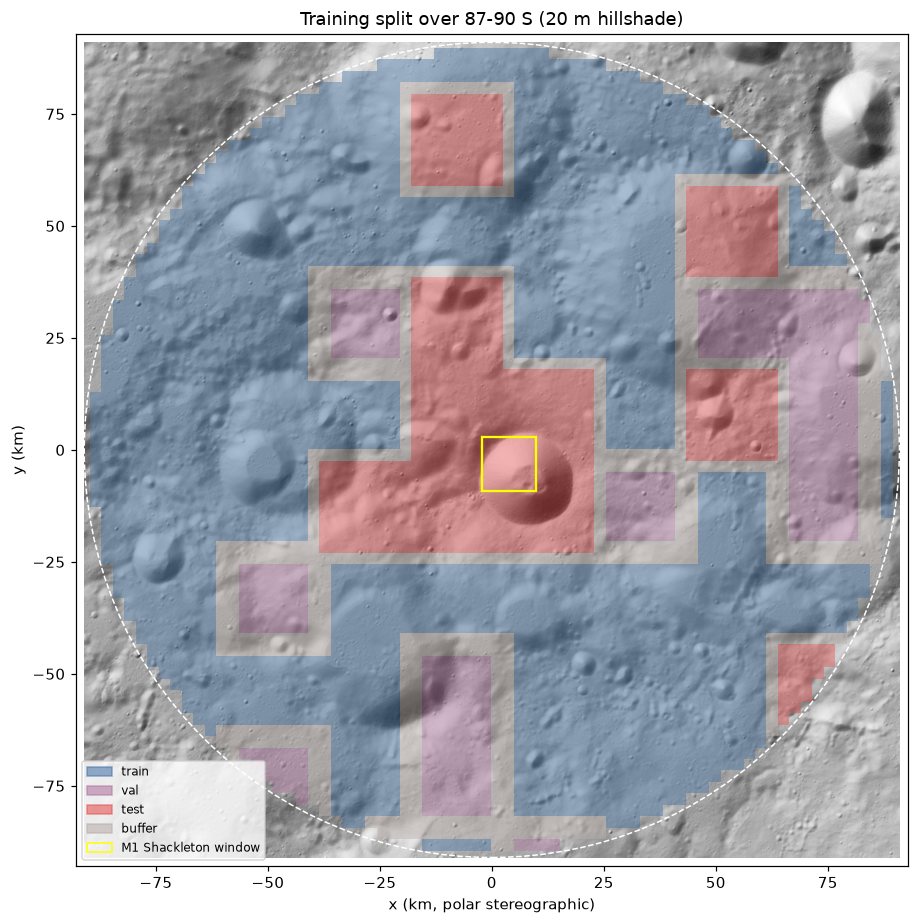

In [8]:
SPLIT_COLORS = {"train": "#4c78a8", "val": "#b279a2", "test": "#e45756", "buffer": "#bab0ac"}
step = 8
hs_small = hillshade(elev20_all[::step, ::step], 20 * step)
extE = [tE.c / 1e3, (tE.c + 20 * elev20_all.shape[1]) / 1e3, (tE.f - 20 * elev20_all.shape[0]) / 1e3, tE.f / 1e3]
fig, ax = plt.subplots(figsize=(8.5, 8.5))
ax.imshow(hs_small, cmap="gray", extent=extE)
for s, col in SPLIT_COLORS.items():
    for x0, y0 in G.loc[G.split == s, ["x0", "y0"]].values:
        ax.add_patch(Rectangle((x0 / 1e3, (y0 - side) / 1e3), side / 1e3, side / 1e3, fc=col, ec="none", alpha=0.45))
l, b, r, t = [v / 1e3 for v in M1_BOUNDS]
ax.add_patch(Rectangle((l, b), r - l, t - b, fill=False, ec="yellow", lw=1.5))
ax.add_patch(plt.Circle((0, 0), R87 / 1e3, fill=False, ec="white", ls="--", lw=1))
ax.legend(handles=[Patch(color=c, alpha=0.6, label=s) for s, c in SPLIT_COLORS.items()]
          + [Patch(ec="yellow", fc="none", label="M1 Shackleton window")], loc="lower left", fontsize=8)
ax.set_xlim(-R87 / 1e3 * 1.02, R87 / 1e3 * 1.02); ax.set_ylim(-R87 / 1e3 * 1.02, R87 / 1e3 * 1.02)
ax.set_title("Training split over 87-90 S (20 m hillshade)")
ax.set_xlabel("x (km, polar stereographic)"); ax.set_ylabel("y (km)")
plt.tight_layout(); plt.savefig(FIG / "M2_split_map.png", dpi=150); plt.show()

## D · Build the patches

For each patch this reads the 5 m elevation (plus a small border), computes 5 m slope and the safe / caution / no-go answer, then cuts the matching 20 m inputs:

| Channel | What it is |
| --- | --- |
| 0 `elev_rel` | 20 m elevation minus the patch average (m), so the model sees shape, not absolute height |
| 1 `slope20` | 20 m slope (deg) |
| 2 `bump20` | 20 m bumpiness: how far a pixel sits above or below its neighbours (m) |
| 3 `hill20` | 20 m hillshade (0-1) |
| 4 `logcount20` | log(1 + LOLA shots per 20 m pixel): how much real data is behind the map |
| 5 `psr20` | 1 = permanently shadowed |

It also stores which 5 m pixels have a real LOLA shot, so Milestone 3 can score on real pixels only. The same loop scores the 20 m slope rule (NASA 20 m map) against the 5 m answer. Takes a few minutes; files already written are skipped.

In [9]:
CHANNELS = ["elev_rel", "slope20", "bump20", "hill20", "logcount20", "psr20"]
nC = len(CHANNELS)
ch_sum = np.zeros(nC); ch_sq = np.zeros(nC); ch_n = np.zeros(nC)
cls_count = {s: np.zeros(3, np.int64) for s in ("train", "val", "test")}
rows, skipped = [], 0
H = HALO20
src_e = rasterio.open(F5["elev"]); src_c = rasterio.open(F5["count"])
todo = G[G.split != "buffer"].reset_index(drop=True)
t0 = time.time()
for n, p in todo.iterrows():
    w5 = Window(p.c0 - HALO5, p.r0 - HALO5, PATCH5 + 2 * HALO5, PATCH5 + 2 * HALO5)
    s5 = slope_deg(read_src(src_e, w5), 5)[HALO5:-HALO5, HALO5:-HALO5]
    valid = np.isfinite(s5)
    if valid.mean() < MIN_VALID:
        skipped += 1; continue
    y = classify(s5)
    cnt5 = read_src(src_c, Window(p.c0, p.r0, PATCH5, PATCH5))
    real = (np.nan_to_num(cnt5, nan=0.0) > 0) & valid

    rr, cc = rc20(p.x0, p.y0)
    e20 = elev20_all[rr - H:rr + PATCH20 + H, cc - H:cc + PATCH20 + H].astype("float64")
    if np.isnan(e20).mean() > 0.02:
        skipped += 1; continue
    s20 = slope_deg(e20, 20)[H:-H, H:-H]
    core = e20[H:-H, H:-H]
    x = np.stack([core - np.nanmean(core), s20, bumpiness(e20)[H:-H, H:-H], hillshade(e20, 20)[H:-H, H:-H],
                  logcnt20_all[rr:rr + PATCH20, cc:cc + PATCH20].astype("float32"),
                  psr20_all[rr:rr + PATCH20, cc:cc + PATCH20].astype("float32")]).astype("float32")

    # 20 m slope rule vs 5 m answer
    base = np.repeat(np.repeat(classify(s20), SCALE, 0), SCALE, 1)
    m = (y != NODATA_CLASS) & (base != NODATA_CLASS)
    t_, b_ = (y == 2) & m, (base == 2) & m
    rec = dict(tp=int((t_ & b_).sum()), fn=int((t_ & ~b_).sum()), fp=int((~t_ & b_).sum()),
               tp_real=int((t_ & b_ & real).sum()), fn_real=int((t_ & ~b_ & real).sum()),
               fp_real=int((~t_ & b_ & real).sum()))

    if p.split == "train":
        f = np.isfinite(x)
        for k_ in range(nC):
            v = x[k_][f[k_]].astype("float64")
            ch_sum[k_] += v.sum(); ch_sq[k_] += (v ** 2).sum(); ch_n[k_] += v.size
    cls_count[p.split] += np.bincount(y[y != NODATA_CLASS], minlength=3)[:3]

    pid = f"p{p.i:03d}_{p.j:03d}"
    out = PATCHES / f"{pid}.npz"
    if OVERWRITE or not out.exists():
        np.savez_compressed(out, x=x.astype("float16"), y=y, real=np.packbits(real))
    lat, lon = xy_to_latlon(p.x0 + side / 2, p.y0 - side / 2)
    nogo_frac = float((y == 2).sum() / max(1, (y != NODATA_CLASS).sum()))
    rows.append(dict(id=pid, i=p.i, j=p.j, split=p.split, x0=p.x0, y0=p.y0, lat=float(lat), lon=float(lon),
                     valid_frac=float(valid.mean()), real_frac=float(real.mean()), nogo_frac=nogo_frac,
                     psr_frac=float(x[5].mean()), in_m1=bool(p.in_m1), **rec))
    if (n + 1) % 200 == 0 or n + 1 == len(todo):
        print(f"\r  {n + 1:,}/{len(todo):,} patches, {time.time() - t0:.0f} s", end="", flush=True)
src_e.close(); src_c.close()

idx = pd.DataFrame(rows)
bins = [b[0] for b in STRATA] + [STRATA[-1][1]]
idx["terrain"] = pd.cut(idx.nogo_frac, bins=bins, labels=[b[2] for b in STRATA], right=False).astype(str)
idx.to_csv(PATCHES / "index.csv", index=False)
print(f"\nWrote {len(idx):,} patches to {PATCHES} (skipped {skipped} with missing data)")
print(idx.groupby(["split", "terrain"]).size().unstack(fill_value=0))

  3,230/3,230 patches, 81 s
Wrote 3,230 patches to /Users/razbinkarkidoli/lunar/data/patches (skipped 0 with missing data)
terrain  mixed  mostly drivable  mostly steep
split                                        
test        44              514            41
train       74             2136            24
val         12              382             3


## E · How good is the plain 20 m slope rule across the whole 87–90°S area?

Same scores as Milestone 1 (no-go recall = share of real 5 m no-go pixels the rule also flags), now on NASA's 20 m map, summed over all patches and split by terrain type. **Missing a cliff is worse than a false alarm, so recall matters most.** If recall in "mostly drivable" terrain is well below the M1 98%, that gap is what the U-Net is for.

In [10]:
def table(df, by):
    out = []
    for key, g in df.groupby(by):
        rec, prec, f1 = prf(g.tp.sum(), g.fn.sum(), g.fp.sum())
        rec_r, prec_r, f1_r = prf(g.tp_real.sum(), g.fn_real.sum(), g.fp_real.sum())
        out.append(dict(zip(by, key if isinstance(key, tuple) else (key,)), patches=len(g),
                        truth_nogo_px=int(g.tp.sum() + g.fn.sum()),
                        nogo_recall=rec, nogo_precision=prec, nogo_f1=f1,
                        recall_real_px=rec_r, f1_real_px=f1_r))
    return pd.DataFrame(out)

idx_all = idx.assign(scope="all 87-90 S")
E_overall = table(idx_all, ["scope"])
E_terrain = table(idx, ["terrain"])
E_split = table(idx, ["split", "terrain"])
print("Whole area (measured):"); display(E_overall.round(3))
print("By terrain (measured):"); display(E_terrain.round(3))
print("By split and terrain (measured). Milestone 3 must beat the 'test' rows:"); display(E_split.round(3))

Whole area (measured):


,scope,patches,truth_nogo_px,nogo_recall,nogo_precision,nogo_f1,recall_real_px,f1_real_px
0,all 87-90 S,3230,26551293,0.808,0.864,0.835,0.793,0.828


By terrain (measured):


,terrain,patches,truth_nogo_px,nogo_recall,nogo_precision,nogo_f1,recall_real_px,f1_real_px
0,mixed,130,7695929,0.738,0.784,0.760,0.708,0.740
1,mostly drivable,3032,4268940,0.388,0.666,0.490,0.297,0.411
2,mostly steep,68,14586424,0.968,0.935,0.951,0.969,0.947


By split and terrain (measured). Milestone 3 must beat the 'test' rows:


,split,terrain,patches,truth_nogo_px,nogo_recall,nogo_precision,nogo_f1,recall_real_px,f1_real_px
0,test,mixed,44,2452394,0.751,0.800,0.775,0.735,0.766
1,test,mostly drivable,514,1088512,0.383,0.684,0.491,0.308,0.427
2,test,mostly steep,41,9360668,0.984,0.956,0.970,0.983,0.963
3,train,mixed,74,4564328,0.730,0.774,0.752,0.685,0.719
4,train,mostly drivable,2136,2747100,0.392,0.660,0.492,0.296,0.408
5,train,mostly steep,24,4687874,0.941,0.900,0.920,0.934,0.906
6,val,mixed,12,679207,0.747,0.790,0.768,0.732,0.756
7,val,mostly drivable,382,433328,0.378,0.660,0.481,0.267,0.380
8,val,mostly steep,3,537882,0.914,0.866,0.890,0.899,0.867


## F · What the model will see

Three test patches, one per terrain type, picked where the 20 m rule misses the most no-go pixels. Columns: two of the six inputs, the 5 m answer, the 20 m rule, and the misses in red.

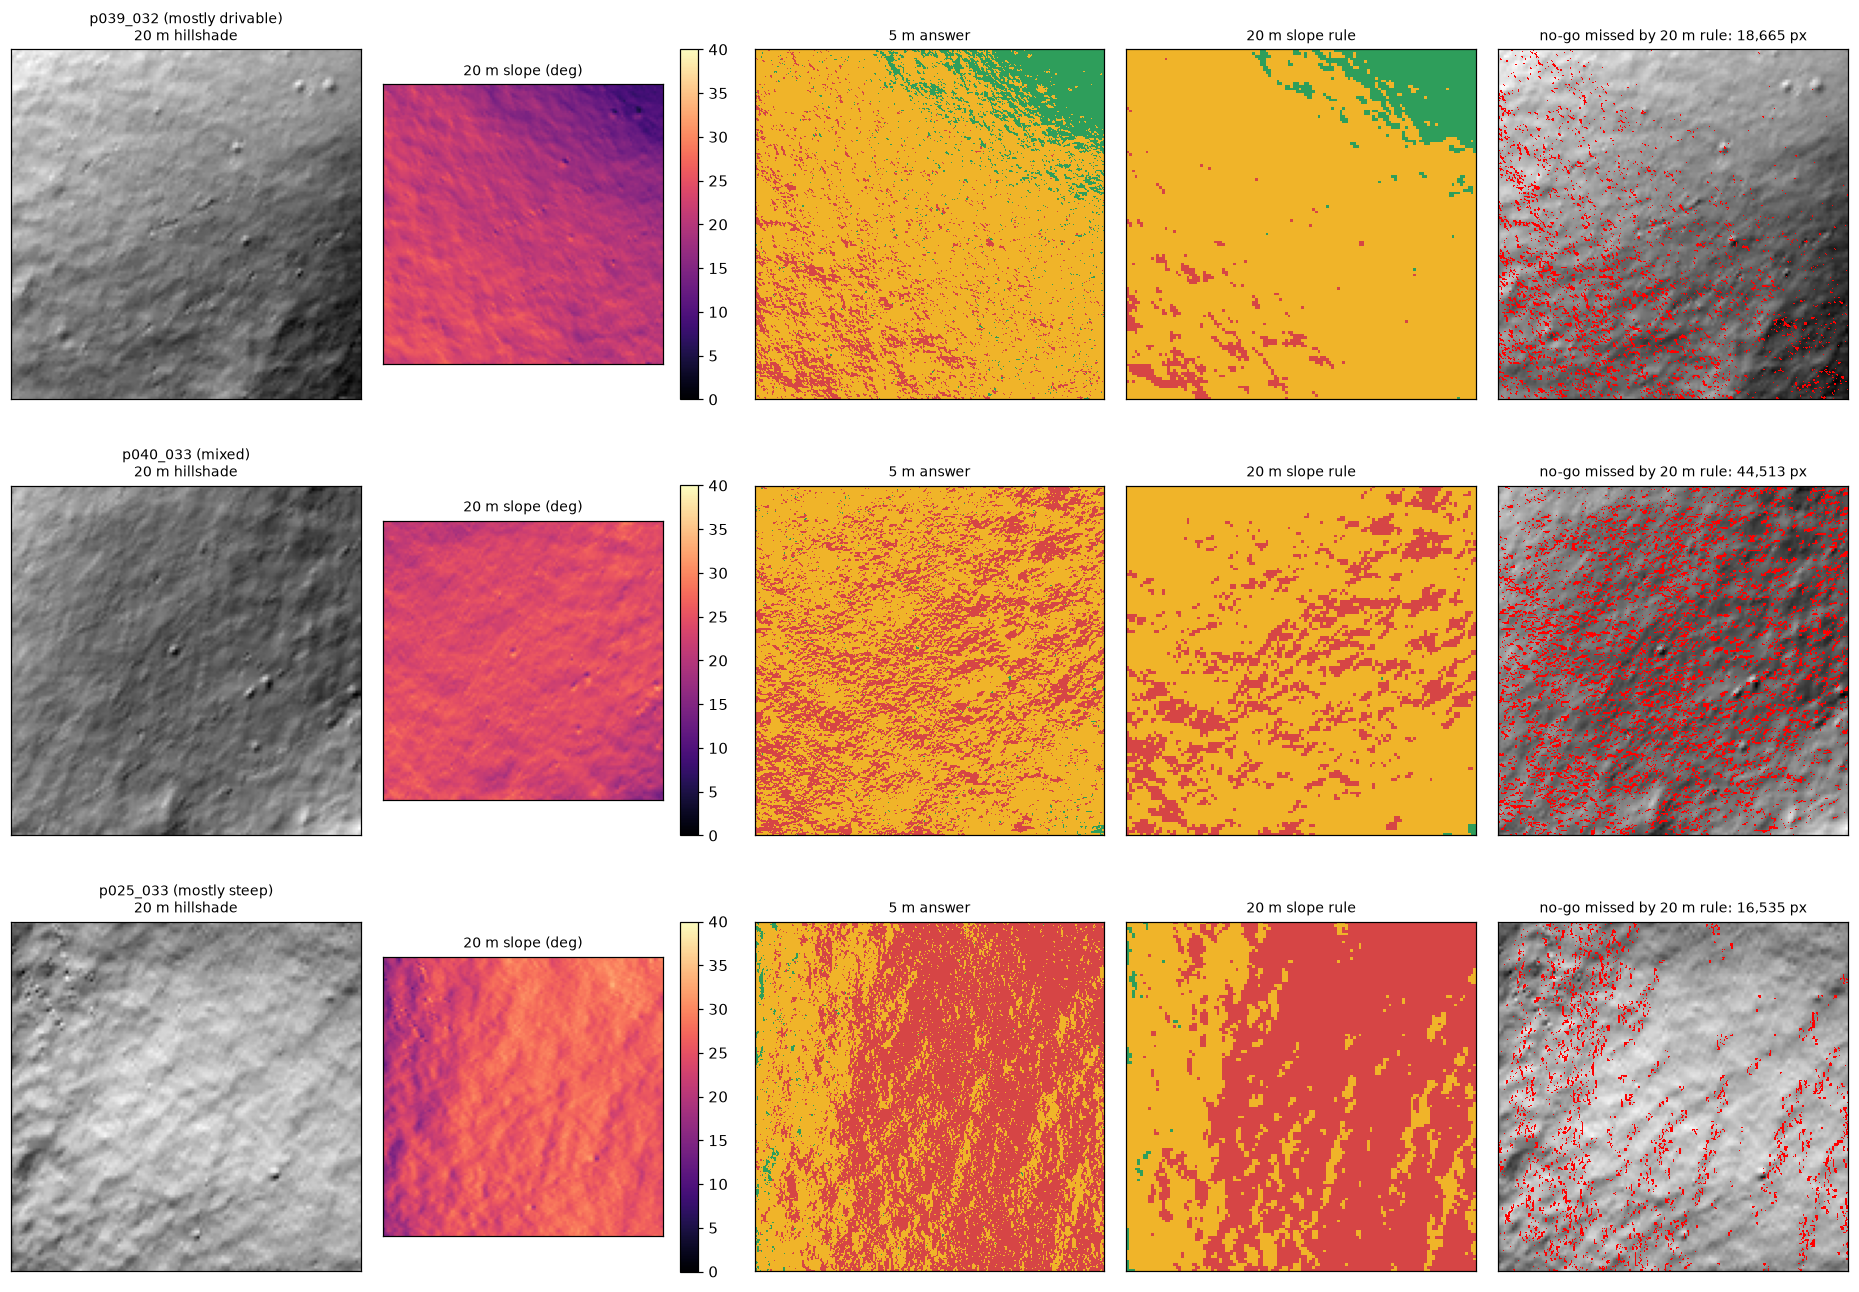

In [11]:
test = idx[idx.split == "test"]
picks = [test[test.terrain == t].sort_values("fn").iloc[-1] for t in [s[2] for s in STRATA] if (test.terrain == t).any()]
if picks:
    fig, axes = plt.subplots(len(picks), 5, figsize=(17, 4.1 * len(picks)), squeeze=False)
    for ax_row, p in zip(axes, picks):
        z = np.load(PATCHES / f"{p.id}.npz")
        x = z["x"].astype("float32"); y = z["y"]
        base = np.repeat(np.repeat(classify(x[1]), SCALE, 0), SCALE, 1)
        miss = (y == 2) & (base != 2)
        ex = [0, side / 1e3, 0, side / 1e3]
        ax_row[0].imshow(x[3], cmap="gray", extent=ex); ax_row[0].set_title(f"{p.id} ({p.terrain})\n20 m hillshade", fontsize=9)
        im = ax_row[1].imshow(x[1], cmap="magma", vmin=0, vmax=40, extent=ex); ax_row[1].set_title("20 m slope (deg)", fontsize=9)
        plt.colorbar(im, ax=ax_row[1], shrink=0.8)
        show_classes(ax_row[2], y, ex, "5 m answer")
        show_classes(ax_row[3], base, ex, "20 m slope rule")
        ax_row[4].imshow(x[3], cmap="gray", extent=ex)
        ax_row[4].imshow(np.ma.masked_where(~miss, miss), cmap=ListedColormap(["red"]), extent=ex, interpolation="nearest")
        ax_row[4].set_title(f"no-go missed by 20 m rule: {miss.sum():,} px", fontsize=9)
        for a in ax_row: a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.savefig(FIG / "M2_example_patches.png", dpi=150); plt.show()

## G · Numbers Milestone 3 needs

Input scaling (mean and spread of each channel, from **train** patches only) and class weights for the loss. Then everything goes into `results/m2_summary.json`.

In [12]:
mean = ch_sum / np.maximum(ch_n, 1)
std = np.sqrt(np.maximum(ch_sq / np.maximum(ch_n, 1) - mean ** 2, 1e-12))
norm = pd.DataFrame(dict(channel=CHANNELS, mean=mean, std=std))
display(norm.round(4))

tr = cls_count["train"].astype(float)
weights = tr.sum() / (3 * np.maximum(tr, 1))       # inverse class frequency (a starting point, setting)
shares = {s: dict(zip(CLASS_NAMES, (c / max(1, c.sum())).round(4).tolist())) for s, c in cls_count.items()}
print("Class shares per split (measured):", shares)
print("Class weights for the loss (from train):", dict(zip(CLASS_NAMES, weights.round(3).tolist())))

def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)): return None if not np.isfinite(o) else round(float(o), 5)
    if isinstance(o, np.integer): return int(o)
    return o

summary = clean({
    "settings": {
        "safe_max_deg": {"value": SAFE_MAX_DEG, "label": "sourced: NASA VIPER page"},
        "nogo_min_deg": {"value": NOGO_MIN_DEG, "label": "placeholder: project plan"},
        "patch_5m_px": PATCH5, "patch_20m_px": PATCH20, "block_patches": BLOCK, "seed": SEED,
        "split_frac": SPLIT_FRAC, "strata": [list(s) for s in STRATA], "min_valid": MIN_VALID,
        "channels": CHANNELS, "grid_shift_5m_px": [r_shift, c_shift],
    },
    "measured": {
        "B_m1_window_recheck": B,
        "patches_per_split": idx.split.value_counts().to_dict(),
        "patches_per_split_terrain": idx.groupby(["split", "terrain"]).size().unstack(fill_value=0).to_dict(orient="index"),
        "class_shares": shares,
        "E_baseline_overall": E_overall.drop(columns="scope").to_dict(orient="records"),
        "E_baseline_by_terrain": E_terrain.to_dict(orient="records"),
        "E_baseline_by_split_terrain": E_split.to_dict(orient="records"),
        "real_px_share": float(idx.real_frac.mean()),
        "psr_share": float(idx.psr_frac.mean()),
    },
    "for_milestone_3": {"channel_mean": mean.tolist(), "channel_std": std.tolist(),
                        "class_weights": weights.tolist(),
                        "note": "normalise x with these, then replace any NaN with 0"},
    "data_citations": ["Barker et al. 2023, PSJ 4, 183, doi:10.3847/PSJ/acf3e1",
                       "Barker et al. 2021, PSS 203, 105119, doi:10.1016/j.pss.2020.105119"],
})
(RESULTS / "m2_summary.json").write_text(json.dumps(summary, indent=2))
print("Wrote", RESULTS / "m2_summary.json")

,channel,mean,std
0,elev_rel,0.0000,135.8105
1,slope20,9.9429,6.1762
2,bump20,0.9811,1.1196
3,hill20,0.6937,0.0991
4,logcount20,0.6397,0.5169
5,psr20,0.1880,0.3907


Class shares per split (measured): {'train': {'safe': 0.7841, 'caution': 0.1954, 'no-go': 0.0205}, 'val': {'safe': 0.7539, 'caution': 0.2303, 'no-go': 0.0159}, 'test': {'safe': 0.675, 'caution': 0.2428, 'no-go': 0.0822}}
Class weights for the loss (from train): {'safe': 0.425, 'caution': 1.706, 'no-go': 16.268}
Wrote results/m2_summary.json


## What to look at before Milestone 3

- **Section B:** if the NASA 20 m rule scores lower than the M1 method on the Shackleton window, M1's 98% was optimistic. If it reports a best shift other than [0, 0], stop and fix alignment before training.
- **Section E, "mostly drivable" row:** this is where rover routes go. Its no-go recall is the number the U-Net has to beat. If it's already about 98%, the honest result is "the 20 m rule is enough" and the proposal uses the rule-based map.
- **Section C map:** test blocks should cover a mix of crater walls and flatter ground, not only one kind.

Next notebook: `03_train_hazard.ipynb` trains the U-Net on these patches (128 × 128 inputs → 512 × 512 answers) and scores it on the test split against the 20 m rule.